In [1]:
import pandas as pd

train = pd.read_csv("train_temporal.csv")
val = pd.read_csv("val_temporal.csv")

# Count epochs in each continuous segment
train_lengths = train.groupby("segment").size()
val_lengths = val.groupby("segment").size()

# Summary statistics
print("TRAIN SEGMENT LENGTHS:")
print(train_lengths.describe())

print("\nVALIDATION SEGMENT LENGTHS:")
print(val_lengths.describe())

TRAIN SEGMENT LENGTHS:
count     487.000000
mean      287.022587
std       337.662544
min         1.000000
25%         9.000000
50%       110.000000
75%       570.000000
max      1099.000000
dtype: float64

VALIDATION SEGMENT LENGTHS:
count     157.000000
mean      163.541401
std       286.004964
min         1.000000
25%         4.000000
50%        12.000000
75%       144.000000
max      1083.000000
dtype: float64


In [2]:
sequence_length = 20

print("TRAIN:")
print("Total segments:", len(train_lengths))
print("Segments >= 20:", (train_lengths >= 20).sum())
print("Segments < 20:", (train_lengths < 20).sum())

print("\nVALIDATION:")
print("Total segments:", len(val_lengths))
print("Segments >= 20:", (val_lengths >= 20).sum())
print("Segments < 20:", (val_lengths < 20).sum())

TRAIN:
Total segments: 487
Segments >= 20: 325
Segments < 20: 162

VALIDATION:
Total segments: 157
Segments >= 20: 67
Segments < 20: 90


In [3]:
sequence_length = 20

# Number of complete sequences
train_sequences = (train_lengths - sequence_length + 1).clip(lower=0).sum()
val_sequences = (val_lengths - sequence_length + 1).clip(lower=0).sum()

print("TRAIN:")
print("Total epochs:", len(train))
print("Available sequences:", train_sequences)
print("Coverage:", round(train_sequences / len(train) * 100, 2), "%")

print("\nVALIDATION:")
print("Total epochs:", len(val))
print("Available sequences:", val_sequences)
print("Coverage:", round(val_sequences / len(val) * 100, 2), "%")

TRAIN:
Total epochs: 139780
Available sequences: 132616
Coverage: 94.87 %

VALIDATION:
Total epochs: 25676
Available sequences: 23851
Coverage: 92.89 %


In [4]:
import numpy as np
from sklearn.preprocessing import StandardScaler

base_features = [
    "hr_mean", "hr_std", "hr_min", "hr_max",
    "motion_mean", "motion_std", "motion_min", "motion_max"
]

# Check for missing values
print("Train missing:", train[base_features].isna().sum().sum())
print("Validation missing:", val[base_features].isna().sum().sum())

# Fit scaler on training data only
scaler_gru = StandardScaler()

X_train_scaled = scaler_gru.fit_transform(train[base_features])
X_val_scaled = scaler_gru.transform(val[base_features])

# Convert to float32 for Keras
X_train_scaled = X_train_scaled.astype("float32")
X_val_scaled = X_val_scaled.astype("float32")

print("\nTrain shape:", X_train_scaled.shape)
print("Validation shape:", X_val_scaled.shape)

print("\nTraining feature means:")
print(np.round(X_train_scaled.mean(axis=0), 2))

Train missing: 0
Validation missing: 0

Train shape: (139780, 8)
Validation shape: (25676, 8)

Training feature means:
[ 0.  0.  0. -0. -0.  0. -0.  0.]


In [5]:
def create_sequences(df, X_scaled, sequence_length=20):
    X_sequences = []
    y_sequences = []

    # Keep each sequence inside one continuous segment
    groups = df.groupby(["person", "night", "segment"], sort=False)

    for _, group in groups:
        indices = group.index.to_numpy()
        labels = group["stage_4"].to_numpy()

        for i in range(sequence_length - 1, len(group)):
            # Current and previous 19 epochs
            start = i - sequence_length + 1

            X_sequences.append(X_scaled[indices[start:i+1]])

            # Sleep stage of the current epoch
            y_sequences.append(labels[i])

    return (
        np.array(X_sequences, dtype="float32"),
        np.array(y_sequences, dtype="int32")
    )


# Create GRU datasets
X_train_gru, y_train_gru = create_sequences(train, X_train_scaled)
X_val_gru, y_val_gru = create_sequences(val, X_val_scaled)

print("X_train:", X_train_gru.shape)
print("y_train:", y_train_gru.shape)

print("\nX_val:", X_val_gru.shape)
print("y_val:", y_val_gru.shape)

X_train: (132616, 20, 8)
y_train: (132616,)

X_val: (23851, 20, 8)
y_val: (23851,)


# 10 Minutes GRU

In [6]:
from keras import Sequential
from keras.layers import Input, GRU, Dense, Dropout
from keras.optimizers import Adam
from keras.utils import set_random_seed

set_random_seed(42)

model_gru = Sequential([
    Input(shape=(20, 8)),
    GRU(32),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(4, activation="softmax")
])

model_gru.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_gru.summary()

I0000 00:00:1794331492.996643   39228 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794331493.027961   39228 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI AVX_VNNI_INT8 AVX_NE_CONVERT FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794331494.600416   39228 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
W0000 00:00:1794331495.951009   39228 gpu_device.cc:2453] TensorFlow was not built with CUDA kernel binar

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 32)             │         4,032 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │            68 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,628 (18.08 KB)

 Trainable params: 4,628 (18.08 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
from keras.callbacks import EarlyStopping

# Same soft class weights as our previous model
soft_weights = {
    0: 1.5295399750627603,
    1: 0.7522705172835694,
    2: 1.148662739989314,
    3: 0.9770224004489462
}

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_gru = model_gru.fit(
    X_train_gru,
    y_train_gru,
    validation_data=(X_val_gru, y_val_gru),
    epochs=100,
    batch_size=256,
    class_weight=soft_weights,
    callbacks=[early_stop]
)

Epoch 1/100


I0000 00:00:1794331499.506826   39343 cuda_dnn.cc:442] Loaded cuDNN version 92700


519/519 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.4619 - loss: 1.0828 - val_accuracy: 0.5134 - val_loss: 1.0438
Epoch 2/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.5062 - loss: 1.0197 - val_accuracy: 0.5100 - val_loss: 1.0384
Epoch 3/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.5190 - loss: 1.0063 - val_accuracy: 0.5108 - val_loss: 1.0348
Epoch 4/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.5265 - loss: 0.9954 - val_accuracy: 0.5165 - val_loss: 1.0298
Epoch 5/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.5334 - loss: 0.9859 - val_accuracy: 0.5212 - val_loss: 1.0240
Epoch 6/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.5372 - loss: 0.9768 - val_accuracy: 0.5242 - val_loss: 1.0204
Epoch 7/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.5439 - loss: 0.9681 - val_accuracy: 0.5329 - val_loss: 1.0095
Epoch 8/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.5514 - loss: 0.9584 - val_accuracy: 

In [8]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)
import numpy as np

# Predict validation sleep stages
y_pred_gru = np.argmax(
    model_gru.predict(X_val_gru),
    axis=1
)

# Calculate metrics
accuracy = accuracy_score(y_val_gru, y_pred_gru)
macro_f1 = f1_score(y_val_gru, y_pred_gru, average="macro")

print(f"Validation Accuracy: {accuracy:.2%}")
print(f"Macro F1: {macro_f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_val_gru,
    y_pred_gru,
    labels=[0, 1, 2, 3],
    target_names=["Wake", "Light", "Deep", "REM"],
    zero_division=0
))

746/746 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step
Validation Accuracy: 55.05%
Macro F1: 0.5531

Classification Report:
              precision    recall  f1-score   support

        Wake       0.58      0.56      0.57      2084
       Light       0.59      0.52      0.55     11002
        Deep       0.51      0.60      0.55      4463
         REM       0.51      0.57      0.54      6302

    accuracy                           0.55     23851
   macro avg       0.55      0.56      0.55     23851
weighted avg       0.56      0.55      0.55     23851



In [9]:
import joblib
from keras.models import load_model
from sklearn.metrics import accuracy_score, f1_score

# Load our previous best Dense model
dense_model = load_model("sleep_nn_18.keras")
dense_scaler = joblib.load("sleep_scaler_18.pkl")
dense_features = joblib.load("sleep_features_18.pkl")

# Find the final epoch of every GRU sequence
end_indices = []

for _, group in val.groupby(
    ["person", "night", "segment"], sort=False
):
    end_indices.extend(group.index[19:])

# Confirm targets match
assert np.array_equal(
    val.loc[end_indices, "stage_4"].to_numpy(),
    y_val_gru
)

# Scale the same validation epochs
X_dense = dense_scaler.transform(
    val.loc[end_indices, dense_features]
)

# Predict with the Dense model
y_pred_dense = np.argmax(
    dense_model.predict(X_dense),
    axis=1
)

print("Dense NN (same validation epochs):")
print("Accuracy:", round(accuracy_score(y_val_gru, y_pred_dense), 4))
print("Macro F1:", round(f1_score(y_val_gru, y_pred_dense, average="macro"), 4))

print("\nGRU:")
print("Accuracy:", round(accuracy_score(y_val_gru, y_pred_gru), 4))
print("Macro F1:", round(f1_score(y_val_gru, y_pred_gru, average="macro"), 4))

I0000 00:00:1794331620.843304   39345 service.cc:154] XLA service 0x711bf469d860 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1794331620.843324   39345 service.cc:170]   StreamExecutor [0]: NVIDIA GeForce RTX 5070, Compute Capability 12.0a (Driver: 13.3.0[610.88.0]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1794331620.848211   39345 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.


189/746 ━━━━━━━━━━━━━━━━━━━━ 0s 811us/step

I0000 00:00:1794331621.423522   39345 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


746/746 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
Dense NN (same validation epochs):
Accuracy: 0.509
Macro F1: 0.4827

GRU:
Accuracy: 0.5505
Macro F1: 0.5531


In [10]:
import joblib

# Save trained GRU model
model_gru.save("sleep_gru_20x9.keras")

# Save the scaler fitted on training data
joblib.dump(scaler_gru, "sleep_gru_scaler.pkl")

# Save feature names and their order
joblib.dump(base_features, "sleep_gru_features.pkl")

print("GRU model and preprocessing files saved successfully!")

GRU model and preprocessing files saved successfully!


In [12]:
import joblib
import numpy as np
from sklearn.preprocessing import StandardScaler

# Load our 17 feature names
features_17 = joblib.load("sleep_features_17.pkl")

print("Number of features:", len(features_17))
print(features_17)

# Check for missing values
print("\nTrain missing:", train[features_17].isna().sum().sum())
print("Validation missing:", val[features_17].isna().sum().sum())

# Create new scaler
scaler_gru_17 = StandardScaler()

# Fit on training only
X_train_scaled_17 = scaler_gru_17.fit_transform(
    train[features_17]
).astype("float32")

X_val_scaled_17 = scaler_gru_17.transform(
    val[features_17]
).astype("float32")

print("\nTrain shape:", X_train_scaled_17.shape)
print("Validation shape:", X_val_scaled_17.shape)

print("\nTraining feature means:")
print(np.round(X_train_scaled_17.mean(axis=0), 2))

Number of features: 17
['hr_mean', 'hr_std', 'hr_min', 'hr_max', 'motion_mean', 'motion_std', 'motion_min', 'motion_max', 'hr_mean_roll5', 'motion_mean_roll5', 'hr_change', 'hr_mean_roll_std5', 'motion_mean_roll_std5', 'hr_mean_roll20', 'motion_mean_roll20', 'hr_mean_roll_std20', 'motion_mean_roll_std20']

Train missing: 0
Validation missing: 0

Train shape: (139780, 17)
Validation shape: (25676, 17)

Training feature means:
[ 0.  0.  0. -0. -0.  0. -0.  0.  0. -0.  0. -0.  0. -0. -0.  0. -0.]


In [13]:
# Create sequences using all 17 features
X_train_gru_17, y_train_gru_17 = create_sequences(
    train,
    X_train_scaled_17,
    sequence_length=20
)

X_val_gru_17, y_val_gru_17 = create_sequences(
    val,
    X_val_scaled_17,
    sequence_length=20
)

# Check shapes
print("X_train:", X_train_gru_17.shape)
print("y_train:", y_train_gru_17.shape)

print("\nX_val:", X_val_gru_17.shape)
print("y_val:", y_val_gru_17.shape)

# Verify targets match our previous GRU
print("\nTraining targets match:",
      np.array_equal(y_train_gru_17, y_train_gru))

print("Validation targets match:",
      np.array_equal(y_val_gru_17, y_val_gru))

X_train: (132616, 20, 17)
y_train: (132616,)

X_val: (23851, 20, 17)
y_val: (23851,)

Training targets match: True
Validation targets match: True


In [14]:
from keras import Sequential
from keras.layers import Input, GRU, Dense, Dropout
from keras.optimizers import Adam
from keras.utils import set_random_seed

set_random_seed(42)

model_gru_17 = Sequential([
    Input(shape=(20, 17)),
    GRU(32),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(4, activation="softmax")
])

model_gru_17.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_gru_17.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_1 (GRU)                     │ (None, 32)             │         4,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │            68 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,492 (21.45 KB)

 Trainable params: 5,492 (21.45 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
from keras.callbacks import EarlyStopping

early_stop_17 = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_gru_17 = model_gru_17.fit(
    X_train_gru_17,
    y_train_gru_17,
    validation_data=(X_val_gru_17, y_val_gru_17),
    epochs=100,
    batch_size=256,
    class_weight=soft_weights,
    callbacks=[early_stop_17]
)

Epoch 1/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.4896 - loss: 1.0407 - val_accuracy: 0.5465 - val_loss: 0.9920
Epoch 2/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.5673 - loss: 0.9415 - val_accuracy: 0.5649 - val_loss: 0.9614
Epoch 3/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.5862 - loss: 0.9166 - val_accuracy: 0.5650 - val_loss: 0.9595
Epoch 4/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.5939 - loss: 0.9039 - val_accuracy: 0.5637 - val_loss: 0.9594
Epoch 5/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.5996 - loss: 0.8945 - val_accuracy: 0.5637 - val_loss: 0.9533
Epoch 6/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.6039 - loss: 0.8864 - val_accuracy: 0.5641 - val_loss: 0.9521
Epoch 7/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.6073 - loss: 0.8777 - val_accuracy: 0.5653 - val_loss: 0.9550
Epoch 8/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.6108 - loss: 0.8718 - 

In [16]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)
import numpy as np

# Predict validation sleep stages
y_pred_gru_17 = np.argmax(
    model_gru_17.predict(X_val_gru_17),
    axis=1
)

# Calculate metrics
accuracy_17 = accuracy_score(y_val_gru_17, y_pred_gru_17)
macro_f1_17 = f1_score(
    y_val_gru_17,
    y_pred_gru_17,
    average="macro"
)

print(f"Validation Accuracy: {accuracy_17:.2%}")
print(f"Macro F1: {macro_f1_17:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_val_gru_17,
    y_pred_gru_17,
    labels=[0, 1, 2, 3],
    target_names=["Wake", "Light", "Deep", "REM"],
    zero_division=0
))

746/746 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step
Validation Accuracy: 57.05%
Macro F1: 0.5605

Classification Report:
              precision    recall  f1-score   support

        Wake       0.51      0.59      0.55      2084
       Light       0.59      0.59      0.59     11002
        Deep       0.56      0.50      0.53      4463
         REM       0.57      0.59      0.58      6302

    accuracy                           0.57     23851
   macro avg       0.56      0.57      0.56     23851
weighted avg       0.57      0.57      0.57     23851



In [17]:
import joblib

# Save model
model_gru_17.save("sleep_gru_20x17.keras")

# Save scaler
joblib.dump(scaler_gru_17, "sleep_gru_17_scaler.pkl")

# Save feature names
joblib.dump(features_17, "sleep_gru_17_features.pkl")

print("17-feature GRU model saved successfully!")

17-feature GRU model saved successfully!


# Finding the Best Sequence Length

In [18]:
sequence_lengths = [10, 20, 40, 60]

for length in sequence_lengths:

    train_count = (train_lengths - length + 1).clip(lower=0).sum()
    val_count = (val_lengths - length + 1).clip(lower=0).sum()

    train_coverage = train_count / len(train) * 100
    val_coverage = val_count / len(val) * 100

    print(f"\nSequence length: {length} epochs")
    print(f"Time: {length * 0.5} minutes")
    print(f"Train sequences: {train_count} ({train_coverage:.2f}%)")
    print(f"Validation sequences: {val_count} ({val_coverage:.2f}%)")


Sequence length: 10 epochs
Time: 5.0 minutes
Train sequences: 136045 (97.33%)
Validation sequences: 24618 (95.88%)

Sequence length: 20 epochs
Time: 10.0 minutes
Train sequences: 132616 (94.87%)
Validation sequences: 23851 (92.89%)

Sequence length: 40 epochs
Time: 20.0 minutes
Train sequences: 126340 (90.38%)
Validation sequences: 22714 (88.46%)

Sequence length: 60 epochs
Time: 30.0 minutes
Train sequences: 120494 (86.20%)
Validation sequences: 21733 (84.64%)


# 20 Minutes GRU

In [19]:
# Create 40-epoch sequences
X_train_gru_40, y_train_gru_40 = create_sequences(
    train,
    X_train_scaled_17,
    sequence_length=40
)

X_val_gru_40, y_val_gru_40 = create_sequences(
    val,
    X_val_scaled_17,
    sequence_length=40
)

# Check shapes
print("X_train:", X_train_gru_40.shape)
print("y_train:", y_train_gru_40.shape)

print("\nX_val:", X_val_gru_40.shape)
print("y_val:", y_val_gru_40.shape)

X_train: (126340, 40, 17)
y_train: (126340,)

X_val: (22714, 40, 17)
y_val: (22714,)


In [20]:
from keras import Sequential
from keras.layers import Input, GRU, Dense, Dropout
from keras.optimizers import Adam
from keras.utils import set_random_seed

set_random_seed(42)

model_gru_40 = Sequential([
    Input(shape=(40, 17)),
    GRU(32),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(4, activation="softmax")
])

model_gru_40.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_gru_40.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_2 (GRU)                     │ (None, 32)             │         4,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │            68 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,492 (21.45 KB)

 Trainable params: 5,492 (21.45 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
from keras.callbacks import EarlyStopping

early_stop_40 = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_gru_40 = model_gru_40.fit(
    X_train_gru_40,
    y_train_gru_40,
    validation_data=(X_val_gru_40, y_val_gru_40),
    epochs=100,
    batch_size=256,
    class_weight=soft_weights,
    callbacks=[early_stop_40]
)

Epoch 1/100
494/494 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - accuracy: 0.4918 - loss: 1.0327 - val_accuracy: 0.5316 - val_loss: 1.0285
Epoch 2/100
494/494 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.5753 - loss: 0.9281 - val_accuracy: 0.5606 - val_loss: 0.9745
Epoch 3/100
494/494 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.5988 - loss: 0.8943 - val_accuracy: 0.5638 - val_loss: 0.9688
Epoch 4/100
494/494 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.6136 - loss: 0.8708 - val_accuracy: 0.5748 - val_loss: 0.9580
Epoch 5/100
494/494 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.6237 - loss: 0.8534 - val_accuracy: 0.5720 - val_loss: 0.9696
Epoch 6/100
494/494 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.6310 - loss: 0.8401 - val_accuracy: 0.5655 - val_loss: 0.9857
Epoch 7/100
494/494 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.6357 - loss: 0.8281 - val_accuracy: 0.5566 - val_loss: 1.0035
Epoch 8/100
494/494 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.6409 - loss: 0.8167 - 

In [22]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)
import numpy as np

# Predict sleep stages
y_pred_gru_40 = np.argmax(
    model_gru_40.predict(X_val_gru_40),
    axis=1
)

# Calculate metrics
accuracy_40 = accuracy_score(
    y_val_gru_40, y_pred_gru_40
)

macro_f1_40 = f1_score(
    y_val_gru_40,
    y_pred_gru_40,
    average="macro"
)

print(f"Validation Accuracy: {accuracy_40:.2%}")
print(f"Macro F1: {macro_f1_40:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_val_gru_40,
    y_pred_gru_40,
    labels=[0, 1, 2, 3],
    target_names=["Wake", "Light", "Deep", "REM"],
    zero_division=0
))

710/710 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step
Validation Accuracy: 57.48%
Macro F1: 0.5502

Classification Report:
              precision    recall  f1-score   support

        Wake       0.44      0.57      0.50      1697
       Light       0.59      0.63      0.61     10456
        Deep       0.55      0.47      0.51      4385
         REM       0.61      0.56      0.58      6176

    accuracy                           0.57     22714
   macro avg       0.55      0.56      0.55     22714
weighted avg       0.58      0.57      0.57     22714



In [24]:
# Identify the target epochs used by both models
groups = val.groupby(
    ["person", "night", "segment"],
    sort=False
)

end_indices_20 = []
end_indices_40 = []

for _, group in groups:
    indices = group.index.to_numpy()

    end_indices_20.extend(indices[19:])
    end_indices_40.extend(indices[39:])

# Select the 20-epoch predictions corresponding
# to the 40-epoch model's target epochs
mask = np.isin(end_indices_20, end_indices_40)

# Verify the same targets are being compared
assert np.array_equal(
    y_val_gru_17[mask],
    y_val_gru_40
)

# Previous GRU predictions on matching epochs
y_pred_20_fair = y_pred_gru_17[mask]

print("Validation samples:", len(y_val_gru_40))

print("\nGRU (20 x 17):")
print("Accuracy:", round(
    accuracy_score(y_val_gru_40, y_pred_20_fair), 4
))
print("Macro F1:", round(
    f1_score(y_val_gru_40, y_pred_20_fair, average="macro"), 4
))

print("\nGRU (40 x 17):")
print("Accuracy:", round(accuracy_40, 4))
print("Macro F1:", round(macro_f1_40, 4))

Validation samples: 22714

GRU (20 x 17):
Accuracy: 0.5704
Macro F1: 0.5548

GRU (40 x 17):
Accuracy: 0.5748
Macro F1: 0.5502


In [25]:
from keras import Sequential
from keras.layers import Input, GRU, Dense, Dropout
from keras.optimizers import Adam
from keras.utils import set_random_seed

set_random_seed(42)

model_gru_64 = Sequential([
    Input(shape=(20, 17)),
    GRU(64),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(4, activation="softmax")
])

model_gru_64.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_gru_64.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_3 (GRU)                     │ (None, 64)             │        15,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 4)              │            68 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,044 (66.58 KB)

 Trainable params: 17,044 (66.58 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
from keras.callbacks import EarlyStopping

early_stop_64 = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_gru_64 = model_gru_64.fit(
    X_train_gru_17,
    y_train_gru_17,
    validation_data=(X_val_gru_17, y_val_gru_17),
    epochs=100,
    batch_size=256,
    class_weight=soft_weights,
    callbacks=[early_stop_64]
)

Epoch 1/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.5204 - loss: 1.0054 - val_accuracy: 0.5637 - val_loss: 0.9726
Epoch 2/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.5815 - loss: 0.9228 - val_accuracy: 0.5540 - val_loss: 0.9918
Epoch 3/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.5989 - loss: 0.8972 - val_accuracy: 0.5653 - val_loss: 0.9757
Epoch 4/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.6061 - loss: 0.8799 - val_accuracy: 0.5643 - val_loss: 0.9799
Epoch 5/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.6141 - loss: 0.8647 - val_accuracy: 0.5648 - val_loss: 0.9782
Epoch 6/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.6219 - loss: 0.8498 - val_accuracy: 0.5691 - val_loss: 0.9789
Epoch 7/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.6298 - loss: 0.8348 - val_accuracy: 0.5627 - val_loss: 0.9871
Epoch 8/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.6357 - loss: 0.8191 - 

In [27]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)
import numpy as np

# Predict validation sleep stages
y_pred_gru_64 = np.argmax(
    model_gru_64.predict(X_val_gru_17),
    axis=1
)

# Calculate metrics
accuracy_64 = accuracy_score(
    y_val_gru_17,
    y_pred_gru_64
)

macro_f1_64 = f1_score(
    y_val_gru_17,
    y_pred_gru_64,
    average="macro"
)

print(f"Validation Accuracy: {accuracy_64:.2%}")
print(f"Macro F1: {macro_f1_64:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_val_gru_17,
    y_pred_gru_64,
    labels=[0, 1, 2, 3],
    target_names=["Wake", "Light", "Deep", "REM"],
    zero_division=0
))

746/746 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step
Validation Accuracy: 56.37%
Macro F1: 0.5584

Classification Report:
              precision    recall  f1-score   support

        Wake       0.52      0.53      0.52      2084
       Light       0.59      0.54      0.56     11002
        Deep       0.53      0.66      0.59      4463
         REM       0.58      0.55      0.56      6302

    accuracy                           0.56     23851
   macro avg       0.55      0.57      0.56     23851
weighted avg       0.57      0.56      0.56     23851



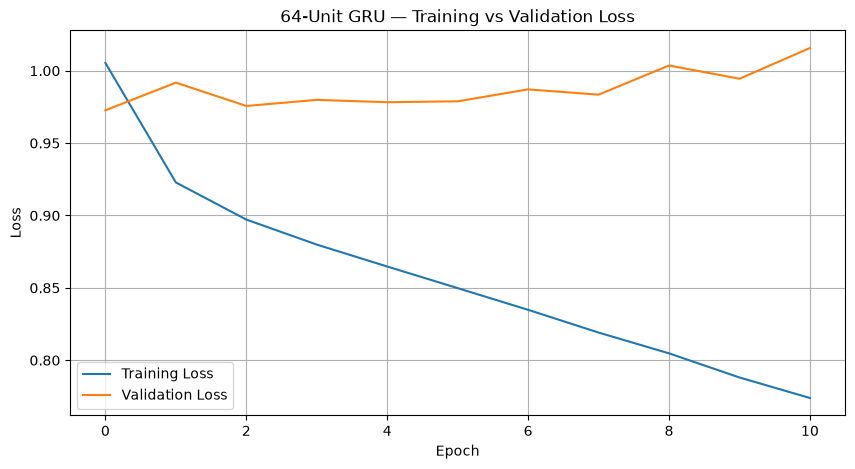

Best epoch: 1
Best validation loss: 0.9726


In [28]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 5))

# 64-unit GRU
plt.plot(history_gru_64.history["loss"], label="Training Loss")
plt.plot(history_gru_64.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("64-Unit GRU — Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

# Find the best epoch
best_epoch = np.argmin(history_gru_64.history["val_loss"]) + 1

print("Best epoch:", best_epoch)
print("Best validation loss:",
      round(min(history_gru_64.history["val_loss"]), 4))

In [29]:
from keras import Sequential
from keras.layers import Input, GRU, Dense, Dropout
from keras.optimizers import Adam
from keras.utils import set_random_seed

set_random_seed(42)

model_gru_dropout = Sequential([
    Input(shape=(20, 17)),
    GRU(64),
    Dropout(0.4),
    Dense(16, activation="relu"),
    Dense(4, activation="softmax")
])

model_gru_dropout.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_gru_dropout.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_4 (GRU)                     │ (None, 64)             │        15,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 4)              │            68 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,044 (66.58 KB)

 Trainable params: 17,044 (66.58 KB)

 Non-trainable params: 0 (0.00 B)

In [30]:
from keras.callbacks import EarlyStopping

early_stop_dropout = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_gru_dropout = model_gru_dropout.fit(
    X_train_gru_17,
    y_train_gru_17,
    validation_data=(X_val_gru_17, y_val_gru_17),
    epochs=100,
    batch_size=256,
    class_weight=soft_weights,
    callbacks=[early_stop_dropout]
)

Epoch 1/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.5117 - loss: 1.0181 - val_accuracy: 0.5649 - val_loss: 0.9711
Epoch 2/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.5727 - loss: 0.9371 - val_accuracy: 0.5486 - val_loss: 0.9977
Epoch 3/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.5912 - loss: 0.9113 - val_accuracy: 0.5641 - val_loss: 0.9783
Epoch 4/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.5995 - loss: 0.8956 - val_accuracy: 0.5724 - val_loss: 0.9731
Epoch 5/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.6080 - loss: 0.8810 - val_accuracy: 0.5729 - val_loss: 0.9682
Epoch 6/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.6159 - loss: 0.8667 - val_accuracy: 0.5794 - val_loss: 0.9616
Epoch 7/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.6216 - loss: 0.8525 - val_accuracy: 0.5822 - val_loss: 0.9634
Epoch 8/100
519/519 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.6287 - loss: 0.8383 - v

In [31]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)
import numpy as np

# Predict validation sleep stages
y_pred_gru_dropout = np.argmax(
    model_gru_dropout.predict(X_val_gru_17),
    axis=1
)

# Calculate metrics
accuracy_dropout = accuracy_score(
    y_val_gru_17,
    y_pred_gru_dropout
)

macro_f1_dropout = f1_score(
    y_val_gru_17,
    y_pred_gru_dropout,
    average="macro"
)

print(f"Validation Accuracy: {accuracy_dropout:.2%}")
print(f"Macro F1: {macro_f1_dropout:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_val_gru_17,
    y_pred_gru_dropout,
    labels=[0, 1, 2, 3],
    target_names=["Wake", "Light", "Deep", "REM"],
    zero_division=0
))

746/746 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step
Validation Accuracy: 57.94%
Macro F1: 0.5735

Classification Report:
              precision    recall  f1-score   support

        Wake       0.52      0.58      0.55      2084
       Light       0.61      0.56      0.58     11002
        Deep       0.55      0.60      0.58      4463
         REM       0.58      0.60      0.59      6302

    accuracy                           0.58     23851
   macro avg       0.56      0.59      0.57     23851
weighted avg       0.58      0.58      0.58     23851



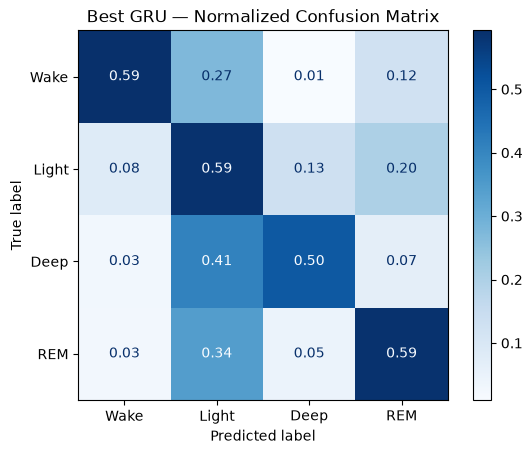

In [32]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

stages = ["Wake", "Light", "Deep", "REM"]

ConfusionMatrixDisplay.from_predictions(
    y_val_gru_17,
    y_pred_gru_17,
    labels=[0, 1, 2, 3],
    display_labels=stages,
    normalize="true",
    cmap="Blues",
    values_format=".2f"
)

plt.title("Best GRU — Normalized Confusion Matrix")
plt.show()

In [33]:
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

# Get previous sleep stage within each segment
previous_stage = val.groupby(
    ["person", "night", "segment"]
)["stage_4"].shift(1)

# Use the same target epochs as our best GRU
indices = np.array(end_indices_20)

# Check alignment
assert np.array_equal(
    val.loc[indices, "stage_4"].to_numpy(),
    y_val_gru_17
)

# Identify stage transitions
is_transition = (
    y_val_gru_17 != previous_stage.loc[indices].to_numpy()
)

# Compare performance
for name, mask in [
    ("Transition epochs", is_transition),
    ("Stable epochs", ~is_transition)
]:
    print(f"\n{name}")
    print("Samples:", mask.sum())

    print("Accuracy:", round(
        accuracy_score(y_val_gru_17[mask], y_pred_gru_17[mask]), 4
    ))

    print("Macro F1:", round(
        f1_score(
            y_val_gru_17[mask],
            y_pred_gru_17[mask],
            labels=[0, 1, 2, 3],
            average="macro",
            zero_division=0
        ), 4
    ))


Transition epochs
Samples: 1064
Accuracy: 0.3994
Macro F1: 0.37

Stable epochs
Samples: 22787
Accuracy: 0.5785
Macro F1: 0.5708


In [34]:
# Create a dataframe containing transition epochs only
transition_df = pd.DataFrame({
    "From": previous_stage.loc[indices].to_numpy()[is_transition].astype(int),
    "To": y_val_gru_17[is_transition],
    "Predicted": y_pred_gru_17[is_transition]
})

# Check whether each prediction was correct
transition_df["Correct"] = (
    transition_df["To"] == transition_df["Predicted"]
)

# Group by transition type
transition_results = (
    transition_df.groupby(["From", "To"])["Correct"]
    .agg(["size", "mean"])
    .reset_index()
)

# Convert stage numbers to names
stage_names = {
    0: "Wake",
    1: "Light",
    2: "Deep",
    3: "REM"
}

transition_results["From"] = transition_results["From"].map(stage_names)
transition_results["To"] = transition_results["To"].map(stage_names)

transition_results = transition_results.rename(
    columns={"size": "Samples", "mean": "Accuracy"}
)

transition_results["Accuracy"] = (
    transition_results["Accuracy"] * 100
).round(2)

# Show most common transitions
print(
    transition_results
    .sort_values("Samples", ascending=False)
    .head(12)
    .to_string(index=False)
)

 From    To  Samples  Accuracy
  REM Light      229     39.30
Light   REM      227     43.17
 Wake Light      190     50.00
Light  Wake      159     27.67
Light  Deep      123     34.96
 Deep Light       82     53.66
 Deep  Wake       28     21.43
 Deep   REM       14     28.57
 Wake  Deep        6      0.00
  REM  Deep        3     33.33
  REM  Wake        2      0.00
 Wake   REM        1      0.00


In [35]:
# Did the model predict the previous sleep stage?
transition_df["Predicted_Previous"] = (
    transition_df["Predicted"] == transition_df["From"]
)

# Analyze each transition type
lag_results = (
    transition_df.groupby(["From", "To"])
    .agg(
        Samples=("Correct", "size"),
        Correct_New=("Correct", "mean"),
        Predicted_Previous=("Predicted_Previous", "mean")
    )
    .reset_index()
)

# Convert to percentages
lag_results["Correct_New"] = (
    lag_results["Correct_New"] * 100
).round(2)

lag_results["Predicted_Previous"] = (
    lag_results["Predicted_Previous"] * 100
).round(2)

# Show the six most common transitions
print(
    lag_results
    .sort_values("Samples", ascending=False)
    .head(6)
    .to_string(index=False)
)

# Overall percentage
print("\nOverall predictions matching previous stage:")
print(round(
    transition_df["Predicted_Previous"].mean() * 100, 2
), "%")

 From  To  Samples  Correct_New  Predicted_Previous
    3   1      229        39.30               45.41
    1   3      227        43.17               43.61
    0   1      190        50.00               29.47
    1   0      159        27.67               50.31
    1   2      123        34.96               54.47
    2   1       82        53.66               35.37

Overall predictions matching previous stage:
42.39 %


# 5 Minutes GRU

In [36]:
X_train_gru_10, y_train_gru_10 = create_sequences(
    train,
    X_train_scaled_17,
    sequence_length=10
)

X_val_gru_10, y_val_gru_10 = create_sequences(
    val,
    X_val_scaled_17,
    sequence_length=10
)

print("Training:", X_train_gru_10.shape)
print("Validation:", X_val_gru_10.shape)

Training: (136045, 10, 17)
Validation: (24618, 10, 17)


In [37]:
from keras import Sequential
from keras.layers import Input, GRU, Dense, Dropout
from keras.optimizers import Adam
from keras.utils import set_random_seed

# Verify the sequence shapes from Step 32.1
assert X_train_gru_10.shape == (136045, 10, 17)
assert X_val_gru_10.shape == (24618, 10, 17)

set_random_seed(42)

model_gru_10 = Sequential([
    Input(shape=(10, 17)),
    GRU(32),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(4, activation="softmax")
])

model_gru_10.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_gru_10.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_5 (GRU)                     │ (None, 32)             │         4,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 4)              │            68 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,492 (21.45 KB)

 Trainable params: 5,492 (21.45 KB)

 Non-trainable params: 0 (0.00 B)

In [38]:
from keras.callbacks import EarlyStopping

early_stop_10 = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_gru_10 = model_gru_10.fit(
    X_train_gru_10,
    y_train_gru_10,
    validation_data=(X_val_gru_10, y_val_gru_10),
    epochs=100,
    batch_size=256,
    class_weight=soft_weights,
    callbacks=[early_stop_10]
)

Epoch 1/100
532/532 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.4797 - loss: 1.0529 - val_accuracy: 0.5348 - val_loss: 1.0121
Epoch 2/100
532/532 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.5468 - loss: 0.9713 - val_accuracy: 0.5501 - val_loss: 0.9851
Epoch 3/100
532/532 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.5660 - loss: 0.9507 - val_accuracy: 0.5561 - val_loss: 0.9729
Epoch 4/100
532/532 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.5733 - loss: 0.9394 - val_accuracy: 0.5548 - val_loss: 0.9726
Epoch 5/100
532/532 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.5779 - loss: 0.9314 - val_accuracy: 0.5560 - val_loss: 0.9689
Epoch 6/100
532/532 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.5819 - loss: 0.9259 - val_accuracy: 0.5571 - val_loss: 0.9678
Epoch 7/100
532/532 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.5858 - loss: 0.9203 - val_accuracy: 0.5599 - val_loss: 0.9629
Epoch 8/100
532/532 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.5879 - loss: 0.9158 - val_accu

In [39]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)
import numpy as np

# Predict validation sleep stages
y_pred_gru_10 = np.argmax(
    model_gru_10.predict(X_val_gru_10),
    axis=1
)

# Calculate metrics
accuracy_10 = accuracy_score(
    y_val_gru_10,
    y_pred_gru_10
)

macro_f1_10 = f1_score(
    y_val_gru_10,
    y_pred_gru_10,
    average="macro"
)

print(f"Validation Accuracy: {accuracy_10:.2%}")
print(f"Macro F1: {macro_f1_10:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_val_gru_10,
    y_pred_gru_10,
    labels=[0, 1, 2, 3],
    target_names=["Wake", "Light", "Deep", "REM"],
    zero_division=0
))

770/770 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Validation Accuracy: 56.07%
Macro F1: 0.5656

Classification Report:
              precision    recall  f1-score   support

        Wake       0.57      0.60      0.58      2385
       Light       0.58      0.53      0.55     11310
        Deep       0.54      0.58      0.56      4533
         REM       0.55      0.58      0.56      6390

    accuracy                           0.56     24618
   macro avg       0.56      0.57      0.57     24618
weighted avg       0.56      0.56      0.56     24618



In [40]:
# Find the validation target indices for 10-epoch sequences
end_indices_10 = []

for _, group in val.groupby(
    ["person", "night", "segment"], sort=False
):
    end_indices_10.extend(group.index[9:])

# Identify the samples shared with the 20-epoch GRU
mask_10 = np.isin(end_indices_10, end_indices_20)

# Confirm targets match
assert np.array_equal(
    y_val_gru_10[mask_10],
    y_val_gru_17
)

# Compare both models
print("Validation samples:", mask_10.sum())

print("\nGRU (10 x 17):")
print("Accuracy:", round(
    accuracy_score(
        y_val_gru_17,
        y_pred_gru_10[mask_10]
    ), 4
))
print("Macro F1:", round(
    f1_score(
        y_val_gru_17,
        y_pred_gru_10[mask_10],
        average="macro"
    ), 4
))

print("\nGRU (20 x 17):")
print("Accuracy:", round(
    accuracy_score(y_val_gru_17, y_pred_gru_17), 4
))
print("Macro F1:", round(
    f1_score(y_val_gru_17, y_pred_gru_17, average="macro"), 4
))

Validation samples: 23851

GRU (10 x 17):
Accuracy: 0.5591
Macro F1: 0.5593

GRU (20 x 17):
Accuracy: 0.5705
Macro F1: 0.5605


# 15 Minutes GRU

In [41]:
# Create 15-minute sequences (30 epochs)
X_train_gru_30, y_train_gru_30 = create_sequences(
    train,
    X_train_scaled_17,
    sequence_length=30
)

X_val_gru_30, y_val_gru_30 = create_sequences(
    val,
    X_val_scaled_17,
    sequence_length=30
)

# Check shapes
print("X_train:", X_train_gru_30.shape)
print("y_train:", y_train_gru_30.shape)

print("\nX_val:", X_val_gru_30.shape)
print("y_val:", y_val_gru_30.shape)

X_train: (129413, 30, 17)
y_train: (129413,)

X_val: (23224, 30, 17)
y_val: (23224,)


In [42]:
from keras import Sequential
from keras.layers import Input, GRU, Dense, Dropout
from keras.optimizers import Adam
from keras.utils import set_random_seed

set_random_seed(42)

model_gru_30 = Sequential([
    Input(shape=(30, 17)),
    GRU(32),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(4, activation="softmax")
])

model_gru_30.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_gru_30.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru_6 (GRU)                     │ (None, 32)             │         4,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 4)              │            68 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,492 (21.45 KB)

 Trainable params: 5,492 (21.45 KB)

 Non-trainable params: 0 (0.00 B)

In [43]:
from keras.callbacks import EarlyStopping

early_stop_30 = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history_gru_30 = model_gru_30.fit(
    X_train_gru_30,
    y_train_gru_30,
    validation_data=(X_val_gru_30, y_val_gru_30),
    epochs=100,
    batch_size=256,
    class_weight=soft_weights,
    callbacks=[early_stop_30]
)

Epoch 1/100
506/506 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.4918 - loss: 1.0361 - val_accuracy: 0.5480 - val_loss: 1.0054
Epoch 2/100
506/506 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.5720 - loss: 0.9328 - val_accuracy: 0.5595 - val_loss: 0.9742
Epoch 3/100
506/506 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.5930 - loss: 0.9014 - val_accuracy: 0.5679 - val_loss: 0.9523
Epoch 4/100
506/506 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.6045 - loss: 0.8833 - val_accuracy: 0.5635 - val_loss: 0.9607
Epoch 5/100
506/506 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.6121 - loss: 0.8701 - val_accuracy: 0.5734 - val_loss: 0.9536
Epoch 6/100
506/506 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.6171 - loss: 0.8592 - val_accuracy: 0.5715 - val_loss: 0.9586
Epoch 7/100
506/506 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.6219 - loss: 0.8486 - val_accuracy: 0.5783 - val_loss: 0.9526
Epoch 8/100
506/506 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.6261 - loss: 0.8413 - 

In [44]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)
import numpy as np

# Predict validation sleep stages
y_pred_gru_30 = np.argmax(
    model_gru_30.predict(X_val_gru_30),
    axis=1
)

# Calculate metrics
accuracy_30 = accuracy_score(
    y_val_gru_30,
    y_pred_gru_30
)

macro_f1_30 = f1_score(
    y_val_gru_30,
    y_pred_gru_30,
    average="macro"
)

print(f"Validation Accuracy: {accuracy_30:.2%}")
print(f"Macro F1: {macro_f1_30:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_val_gru_30,
    y_pred_gru_30,
    labels=[0, 1, 2, 3],
    target_names=["Wake", "Light", "Deep", "REM"],
    zero_division=0
))

726/726 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step
Validation Accuracy: 56.79%
Macro F1: 0.5638

Classification Report:
              precision    recall  f1-score   support

        Wake       0.50      0.58      0.54      1858
       Light       0.60      0.54      0.57     10723
        Deep       0.53      0.62      0.57      4417
         REM       0.58      0.58      0.58      6226

    accuracy                           0.57     23224
   macro avg       0.55      0.58      0.56     23224
weighted avg       0.57      0.57      0.57     23224



In [45]:
# Identify target epochs for both sequence lengths
end_indices_20 = []
end_indices_30 = []

for _, group in val.groupby(
    ["person", "night", "segment"], sort=False
):
    indices = group.index.to_numpy()

    end_indices_20.extend(indices[19:])
    end_indices_30.extend(indices[29:])

# Find shared validation epochs
mask_20 = np.isin(end_indices_20, end_indices_30)

# Verify the targets and their order match
assert np.array_equal(
    np.array(end_indices_20)[mask_20],
    np.array(end_indices_30)
)

assert np.array_equal(
    y_val_gru_17[mask_20],
    y_val_gru_30
)

# Generate fresh predictions
pred_20 = np.argmax(
    model_gru_17.predict(X_val_gru_17, verbose=0),
    axis=1
)

pred_30 = np.argmax(
    model_gru_30.predict(X_val_gru_30, verbose=0),
    axis=1
)

# Fair comparison
for name, predictions in [
    ("10-minute GRU", pred_20[mask_20]),
    ("15-minute GRU", pred_30)
]:
    print(f"\n{name}")
    print("Accuracy:", round(
        accuracy_score(y_val_gru_30, predictions), 4
    ))
    print("Macro F1:", round(
        f1_score(y_val_gru_30, predictions, average="macro"), 4
    ))

# Verify previous 10-minute benchmark
print("\n10-minute GRU on its full validation subset:")
print("Accuracy:", round(
    accuracy_score(y_val_gru_17, pred_20), 4
))
print("Macro F1:", round(
    f1_score(y_val_gru_17, pred_20, average="macro"), 4
))


10-minute GRU
Accuracy: 0.5691
Macro F1: 0.5556

15-minute GRU
Accuracy: 0.5679
Macro F1: 0.5638

10-minute GRU on its full validation subset:
Accuracy: 0.5705
Macro F1: 0.5605
